In [ ]:
# Dataset setup:
# Extract your dataset archive manually in Google Colab or place the extracted folder
# at the dataset path used in the following cells.

Archive:  /content/drive/MyDrive/currency-20260309T053229Z-3-001.zip
   creating: currency/test/india/.ipynb_checkpoints/
  inflating: currency/test/india/india 1009.jpg  
  inflating: currency/train/srilanka/srilanka 1010.jpg  
  inflating: currency/test/india/india 1003.jpg  
  inflating: currency/test/india/india 1000.jpg  
  inflating: currency/test/srilanka/srilanka 983.jpg  
  inflating: currency/test/india/india 974.jpg  
  inflating: currency/test/india/india 1005.jpg  
  inflating: currency/test/srilanka/srilanka 1009.jpg  
  inflating: currency/test/srilanka/srilanka 1001.jpg  
  inflating: currency/test/india/india 962.jpg  
  inflating: currency/train/srilanka/srilanka 1008.jpg  
  inflating: currency/test/srilanka/srilanka 985.jpg  
  inflating: currency/test/india/india 932.jpg  
  inflating: currency/test/srilanka/srilanka 950.jpg  
  inflating: currency/test/india/india 973.jpg  
  inflating: currency/test/srilanka/srilanka 1007.jpg  
  inflating: currency/test/srilanka

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory

# 1. SETTINGS & REPRODUCIBILITY
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 10
dataset_path = "/content/currency/train" # Change this to your local folder

In [ ]:
# 2. LOAD AND PREPROCESS DATA
# Assumes folder structure: dataset/class_a, dataset/class_b...
train_ds = image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names
print(f"Detected Classes: {class_names}")


Found 1616 files belonging to 2 classes.
Using 1293 files for training.
Found 1616 files belonging to 2 classes.
Using 323 files for validation.
Detected Classes: ['india', 'srilanka']


In [ ]:
# Optimize data loading performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)

In [ ]:
# 3. BUILD THE MODEL (Transfer Learning)
# Load pre-trained VGG16 without the top (classification) layer
base_model = tf.keras.applications.VGG16(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze the base model to keep pre-trained weights intact
base_model.trainable = False

In [ ]:
# Create the final model architecture
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Lambda(tf.keras.applications.vgg16.preprocess_input), # VGG16-specific preprocessing
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation='softmax')
])

In [ ]:
# 4. COMPILE AND TRAIN
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

print("\nStarting Training...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_6 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,715,714 (56.14 MB)

 Trainable params: 1,026 (4.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)


Starting Training...
Epoch 1/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 37s 516ms/step - accuracy: 0.6324 - loss: 0.6446 - val_accuracy: 1.0000 - val_loss: 0.4938
Epoch 2/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 10s 240ms/step - accuracy: 0.9265 - loss: 0.4632 - val_accuracy: 1.0000 - val_loss: 0.3724
Epoch 3/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 11s 257ms/step - accuracy: 0.9862 - loss: 0.3498 - val_accuracy: 1.0000 - val_loss: 0.2886
Epoch 4/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 11s 254ms/step - accuracy: 0.9918 - loss: 0.2832 - val_accuracy: 1.0000 - val_loss: 0.2316
Epoch 5/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 11s 254ms/step - accuracy: 0.9965 - loss: 0.2297 - val_accuracy: 1.0000 - val_loss: 0.1889
Epoch 6/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 10s 247ms/step - accuracy: 0.9986 - loss: 0.1989 - val_accuracy: 1.0000 - val_loss: 0.1573
Epoch 7/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 11s 271ms/step - accuracy: 0.9990 - loss: 0.1631 - val_accuracy: 1.0000 - val_loss: 0.1335
Epoch 8/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 13s 308ms/step - accuracy: 1.0000 - l

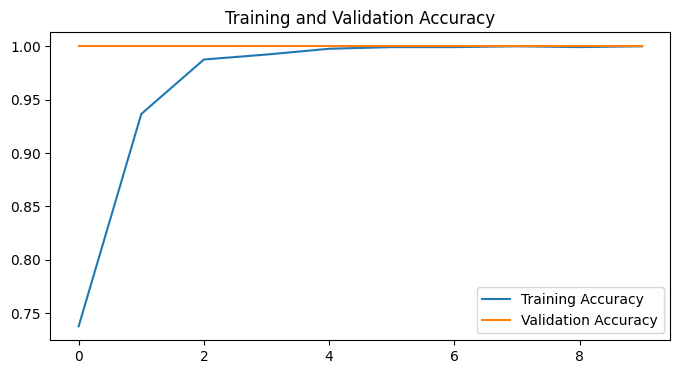

In [ ]:
# 5. VISUALIZE RESULTS
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

plt.figure(figsize=(8, 4))
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.show()

In [ ]:
# 6. MAKE A PREDICTION
img_path="/content/currency/train/srilanka/srilanka 007.jpg"
def predict_image(img_path):
    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_array = tf.expand_dims(img_array, 0) # Create a batch

    predictions = model.predict(img_array)
    score = predictions[0]  # Model already outputs softmax probabilities
    return score
score=predict_image(img_path)
print(f"This image most likely belongs to {class_names[np.argmax(score)]} ")
print(f"with a {100 * np.max(score):.2f} percent confidence.")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
This image most likely belongs to srilanka 
with a 72.35 percent confidence.


### Dataset and execution notes
- Update dataset paths to match the folders available in your environment before running.
- The original CNN architecture and training workflow have been retained.
- Results depend on dataset quality, class balance, folder order, and training configuration.